# 15 — Final Frozen Solution

[Previous](./14_Interpretation_and_Error_Analysis.ipynb) | [Repository guide](../README.md)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** train the already-selected pipeline on all training rows and create the final test predictions.

No method, feature, model weight, calibration rule, or threshold is selected in this notebook.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


## 1. Final pipeline in one view

| Pipeline phase | Frozen decision |
|---|---|
| Problem | Binary classification of `is_scored` |
| Validation evidence | Stratified five-fold OOF; F1 is the main metric |
| IDs | Preserve for output; exclude from model inputs |
| Missing numerical values | Median imputation |
| Missing categorical values | Most-frequent category |
| Numerical scaling | StandardScaler |
| Categorical encoding | One-hot encoding; ignore unseen categories |
| Features | 49 columns after relative-skill, pressure, match-state, interaction, and nonlinear engineering |
| Outliers | Keep original values and rows |
| Class imbalance | Keep the original 55/45 distribution |
| Base models | Tuned CatBoost, LightGBM, and multilayer perceptron |
| Ensemble | Equal arithmetic mean of the three probabilities |
| Calibration | Isotonic regression fitted on training-only OOF probabilities |
| Threshold | `0.50` |

Notebook 14’s strict nested OOF evidence was F1 `0.9491` and ROC-AUC `0.9930`.


## 2. Why create OOF probabilities again?

The final models need all training rows. The calibrator still needs predictions made without seeing each row’s label during model fitting.

Therefore:

1. create five-fold raw OOF ensemble probabilities;
2. fit one isotonic calibrator on those OOF probabilities and all training labels;
3. fit each base model on all training rows;
4. average their test probabilities;
5. apply the frozen calibrator and threshold.

The calibrated training probabilities used to fit the calibrator are **not** reported as a new validation score.


## 3. Organizer-audit boundary

Hidden test labels are not loaded here. The submission and probabilities are saved first.

An organizer may compare the frozen file with hidden labels afterward, once only. That result must not trigger more feature, model, or threshold tuning.


In [1]:
from time import perf_counter
import hashlib
import json
import warnings

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42
FROZEN_THRESHOLD = 0.50

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", message="X does not have valid feature names")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)
assert {"id", TARGET}.issubset(sample_submission.columns)

fingerprint_values = pd.util.hash_pandas_object(
    train.sort_index(axis=1), index=True
).values.tobytes()
dataset_fingerprint = hashlib.sha256(fingerprint_values).hexdigest()[:12]

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Sample submission: {sample_submission.shape}")
print(f"Dataset fingerprint: {dataset_fingerprint}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
Sample submission: (6000, 2)
Dataset fingerprint: 3bc8d73b8f62


In [4]:


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result


X = add_engineered_features(train.drop(columns=[TARGET] + ID_COLUMNS))
y = train[TARGET].astype(int)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y))

print(f"Model inputs: {X.shape[1]} columns before one-hot encoding")
print(f"Numerical: {len(numerical_columns)} | Categorical: {len(categorical_columns)} | Folds: {len(folds)}")

Model inputs: 49 columns before one-hot encoding
Numerical: 44 | Categorical: 5 | Folds: 5


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ], sparse_threshold=0)

In [6]:
base_models = {
    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.025,
        depth=8,
        l2_leaf_reg=5,
        random_strength=0.5,
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=600,
        learning_rate=0.025,
        num_leaves=15,
        max_depth=8,
        min_child_samples=10,
        subsample=1.0,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
    "Multilayer perceptron": MLPClassifier(
        hidden_layer_sizes=(96, 48),
        activation="tanh",
        learning_rate_init=0.003,
        batch_size=256,
        alpha=0.01,
        max_iter=250,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
}

base_summary = pd.DataFrame([
    ["CatBoost", "ordered boosted trees", "strong nonlinear interactions"],
    ["LightGBM", "leaf-wise boosted trees", "fast alternative tree rules"],
    ["Multilayer perceptron", "layers of nonlinear weights", "different learning mechanism"],
], columns=["base model", "how it learns", "why it may add diversity"])
display(base_summary.style.hide(axis="index"))


base model,how it learns,why it may add diversity
CatBoost,ordered boosted trees,strong nonlinear interactions
LightGBM,leaf-wise boosted trees,fast alternative tree rules
Multilayer perceptron,layers of nonlinear weights,different learning mechanism


## 4. Create raw OOF ensemble probabilities

An **OOF probability** is produced by a model that did not train on that row. These probabilities train the final calibrator.

The raw OOF metrics below are a reproducibility sanity check. They do not replace the stricter nested evidence from Notebook 14.


In [7]:
base_oof_probability = {}
oof_start = perf_counter()

for model_name, estimator in base_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", clone(estimator)),
    ])
    model_start = perf_counter()
    class_probabilities = cross_val_predict(
        pipeline,
        X,
        y,
        cv=folds,
        method="predict_proba",
        n_jobs=1,
    )
    # Column 0 = missed; column 1 = scored. Keep the scoring probability.
    base_oof_probability[model_name] = class_probabilities[:, 1]
    print(
        f"Finished {model_name} OOF probabilities in "
        f"{perf_counter() - model_start:.1f}s"
    )

base_oof_matrix = np.column_stack([
    base_oof_probability[name] for name in base_models
])
raw_oof_ensemble = base_oof_matrix.mean(axis=1)

raw_oof_summary = pd.DataFrame([
    [
        "Equal soft ensemble",
        f1_score(y, raw_oof_ensemble >= FROZEN_THRESHOLD),
        roc_auc_score(y, raw_oof_ensemble),
        brier_score_loss(y, raw_oof_ensemble),
    ]
], columns=["model", "raw OOF F1@0.50", "raw OOF ROC-AUC", "raw OOF Brier"])
display(raw_oof_summary.style.hide(axis="index").format(precision=4))
print(f"OOF stage completed in {perf_counter() - oof_start:.1f}s")


Finished CatBoost OOF probabilities in 28.4s
Finished LightGBM OOF probabilities in 10.9s
Finished Multilayer perceptron OOF probabilities in 48.3s


model,raw OOF F1@0.50,raw OOF ROC-AUC,raw OOF Brier
Equal soft ensemble,0.9495,0.9931,0.0330


OOF stage completed in 87.6s


## 5. Fit the frozen calibrator

**Isotonic regression** learns a non-decreasing mapping from raw ensemble scores to observed scoring frequencies.

It is fitted once on all raw OOF probabilities. This mapping is now a final-training component, not a new experiment.


In [8]:
calibrator = IsotonicRegression(out_of_bounds="clip")
calibrator.fit(raw_oof_ensemble, y)

calibration_points = pd.DataFrame({
    "raw_probability": raw_oof_ensemble,
    "actual": y.to_numpy(),
}).sort_values("raw_probability")

print("Final isotonic calibrator fitted on raw OOF probabilities only.")
print(f"Frozen class threshold: {FROZEN_THRESHOLD:.2f}")


Final isotonic calibrator fitted on raw OOF probabilities only.
Frozen class threshold: 0.50


## 6. Train on all rows and predict the test set

Each base model now sees every training row. Their three test probabilities are averaged, calibrated, and converted to classes with threshold `0.50`.


In [9]:
X_test = add_engineered_features(test.drop(columns=ID_COLUMNS))
assert list(X_test.columns) == list(X.columns)

full_models = {}
test_base_probability = {}
fit_start = perf_counter()

for model_name, estimator in base_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", clone(estimator)),
    ])
    model_start = perf_counter()
    pipeline.fit(X, y)
    test_base_probability[model_name] = pipeline.predict_proba(X_test)[:, 1]
    full_models[model_name] = pipeline
    print(
        f"Fitted {model_name} on all rows and predicted test in "
        f"{perf_counter() - model_start:.1f}s"
    )

test_base_matrix = np.column_stack([
    test_base_probability[name] for name in base_models
])
raw_test_ensemble = test_base_matrix.mean(axis=1)
calibrated_test_probability = calibrator.predict(raw_test_ensemble)
final_test_prediction = (
    calibrated_test_probability >= FROZEN_THRESHOLD
).astype(int)

print(f"Full-fit stage completed in {perf_counter() - fit_start:.1f}s")


Fitted CatBoost on all rows and predicted test in 5.9s
Fitted LightGBM on all rows and predicted test in 2.6s
Fitted Multilayer perceptron on all rows and predicted test in 11.2s
Full-fit stage completed in 19.7s


## 7. Final sanity checks

These checks catch file and pipeline mistakes. They do not change the model.

- every sample-submission ID must receive one prediction;
- predictions must contain only `0` and `1`;
- probabilities must stay between `0` and `1`;
- no output value may be missing.


In [10]:
prediction_lookup = pd.Series(
    final_test_prediction,
    index=test["id"],
    name=TARGET,
)
submission = sample_submission[["id"]].copy()
submission[TARGET] = submission["id"].map(prediction_lookup)

assert len(submission) == len(test)
assert submission["id"].is_unique
assert submission[TARGET].notna().all()
assert submission[TARGET].isin([0, 1]).all()
assert np.isfinite(raw_test_ensemble).all()
assert np.isfinite(calibrated_test_probability).all()
assert ((calibrated_test_probability >= 0) & (calibrated_test_probability <= 1)).all()

sanity_summary = pd.DataFrame([
    ["Training actual scoring rate", y.mean()],
    ["Test predicted scoring rate", final_test_prediction.mean()],
    ["Mean raw test probability", raw_test_ensemble.mean()],
    ["Mean calibrated test probability", calibrated_test_probability.mean()],
    ["Minimum calibrated probability", calibrated_test_probability.min()],
    ["Maximum calibrated probability", calibrated_test_probability.max()],
], columns=["check", "value"])
display(sanity_summary.style.hide(axis="index").format({"value": "{:.4f}"}))

print("Submission class counts:")
display(submission[TARGET].value_counts().sort_index().rename("rows").to_frame())


check,value
Training actual scoring rate,0.4501
Test predicted scoring rate,0.4117
Mean raw test probability,0.4139
Mean calibrated test probability,0.4117
Minimum calibrated probability,0.0000
Maximum calibrated probability,1.0000


Submission class counts:


,rows
is_scored,
0,3530
1,2470


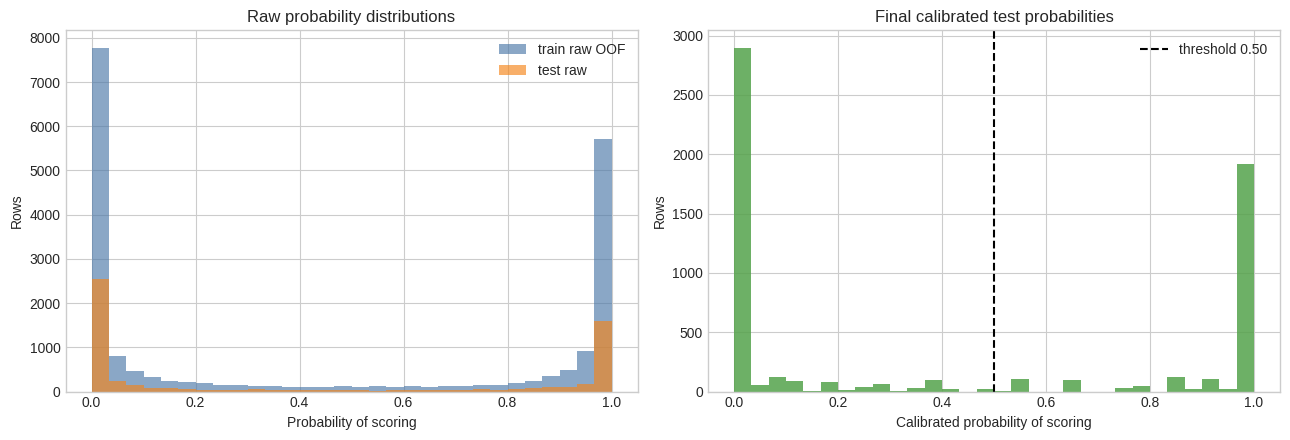

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    raw_oof_ensemble,
    bins=np.linspace(0, 1, 31),
    alpha=0.65,
    label="train raw OOF",
    color="#4C78A8",
)
axes[0].hist(
    raw_test_ensemble,
    bins=np.linspace(0, 1, 31),
    alpha=0.65,
    label="test raw",
    color="#F58518",
)
axes[0].set(
    title="Raw probability distributions",
    xlabel="Probability of scoring",
    ylabel="Rows",
)
axes[0].legend()

axes[1].hist(
    calibrated_test_probability,
    bins=np.linspace(0, 1, 31),
    color="#54A24B",
    alpha=0.85,
)
axes[1].axvline(
    FROZEN_THRESHOLD,
    color="black",
    linestyle="--",
    label="threshold 0.50",
)
axes[1].set(
    title="Final calibrated test probabilities",
    xlabel="Calibrated probability of scoring",
    ylabel="Rows",
)
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Save the frozen artifacts

- `submission.csv`: competition-ready binary predictions.
- `15_test_probabilities.csv`: raw, calibrated, base-model, and final predictions.
- `15_oof_raw_ensemble.csv`: training-only OOF scores used by the calibrator.
- `15_final_pipeline_manifest.json`: fingerprint and frozen decisions for reproducibility.


In [12]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)

# Build the table one column at a time.
table_columns = {}
table_columns['id'] = test['id']
for model_name in base_models:
    table_columns[f'{model_name}_probability'] = test_base_probability[model_name]
table_columns['raw_ensemble_probability'] = raw_test_ensemble
table_columns['calibrated_probability'] = calibrated_test_probability
table_columns['final_prediction'] = final_test_prediction
test_probability_frame = pd.DataFrame(table_columns)

# Build the table one column at a time.
table_columns = {}
table_columns['id'] = train['id']
table_columns['actual'] = y
for model_name in base_models:
    table_columns[f'{model_name}_oof_probability'] = base_oof_probability[model_name]
table_columns['raw_ensemble_oof_probability'] = raw_oof_ensemble
oof_frame = pd.DataFrame(table_columns)

submission.to_csv(results_dir / "submission.csv", index=False)
test_probability_frame.to_csv(
    results_dir / "15_test_probabilities.csv", index=False
)
oof_frame.to_csv(results_dir / "15_oof_raw_ensemble.csv", index=False)

manifest = {
    "dataset_fingerprint": dataset_fingerprint,
    "random_state": RANDOM_STATE,
    "validation_folds": 5,
    "model_input_columns": int(X.shape[1]),
    "base_models": list(base_models),
    "ensemble": "equal arithmetic mean",
    "calibration": "isotonic fitted on five-fold raw OOF ensemble probabilities",
    "threshold": FROZEN_THRESHOLD,
    "raw_oof_f1_at_0_50": float(f1_score(y, raw_oof_ensemble >= FROZEN_THRESHOLD)),
    "raw_oof_roc_auc": float(roc_auc_score(y, raw_oof_ensemble)),
    "test_rows": int(len(test)),
    "predicted_positive_rate": float(final_test_prediction.mean()),
    "model_parameters": {
        name: estimator.get_params() for name, estimator in base_models.items()
    },
}
with (results_dir / "15_final_pipeline_manifest.json").open(
    "w", encoding="utf-8"
) as handle:
    json.dump(manifest, handle, indent=2, default=str)

print(f"Saved frozen final artifacts to: {results_dir}")
print("Final submission preview:")
display(submission.head(10))


Saved frozen final artifacts to: /kaggle/working
Final submission preview:


,id,is_scored
0,20000,1
1,20001,0
2,20002,1
3,20003,0
4,20004,1
5,20005,0
6,20006,0
7,20007,0
8,20008,0
9,20009,0


## 9. Final decision

The prediction file is now frozen. Weighted voting, resampling, alternative calibrators, new features, and threshold changes are not reopened here because they belong to earlier controlled experiments.

The remaining organizer-only audit measures final generalization; it does not select another pipeline.


## Why this decision is justified

**Technical evidence:** every calibrator-training probability is OOF, the three final models use all available training data, and output integrity is checked before saving.

**Theoretical reason:** validation is for choosing a method; final fitting is for using all labeled information after choices are frozen. Keeping those roles separate prevents hidden-label leakage.
